# 04 - The component models and the initial guesses

What the fit adjusts: three analytic components with 14 parameters, their initial
guesses and their allowed ranges. Nothing is fitted here; the curves use the reference
fit of one epoch (`results/fitting/example_run_poisson/`, notebook 00).

**Runtime:** under a minute.

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. The three models

All three are gyrotropic functions of $(v_\parallel, v_\perp)$, the velocity along and
across **B** in the spacecraft frame. For every component
$v_{th} = \sqrt{2 k_B T / m_e}$, so a temperature always means the same thing.

**Core: bi-Maxwellian** (4 parameters: $n_c$, $u_{\parallel c}$, $T_{\parallel c}$, $T_{\perp c}$)

$$ f_c = \frac{n_c}{\pi^{3/2} v_{th\parallel} v_{th\perp}^2}
   \exp\!\left[-\frac{(v_\parallel - u_{\parallel c})^2}{v_{th\parallel}^2} - \frac{v_\perp^2}{v_{th\perp}^2}\right] $$

**Halo: bi-kappa** (5 parameters: $n_h$, $u_{\parallel h}$, $T_{\parallel h}$, $T_{\perp h}$, $\kappa_h$)

$$ f_h = \frac{n_h}{\pi^{3/2} v_{th\parallel} v_{th\perp}^2}\,
   \frac{\Gamma(\kappa + 1)}{(\kappa - 3/2)^{3/2}\,\Gamma(\kappa - 1/2)}
   \left[1 + \frac{(v_\parallel - u_{\parallel h})^2}{(\kappa - 3/2) v_{th\parallel}^2} + \frac{v_\perp^2}{(\kappa - 3/2) v_{th\perp}^2}\right]^{-\kappa - 1} $$

The $(\kappa - 3/2)$ convention makes $T$ the actual second moment. Small $\kappa$ is a
hard power-law tail; $\kappa \to \infty$ is a Maxwellian. The halo drift
$u_{\parallel h}$ is free but kept small (section 3).

**Strahl: drifting, truncated bi-kappa** (5 parameters: $n_b$, $u_{\parallel b}$,
$T_{\parallel b}$, $T_{\perp b}$, $\kappa_b$): a bi-kappa centred at the drift
$u_{\parallel b}$ whose parallel width is divided by $\sqrt{D}$, $D = 5$, on the side
facing the core, so the beam cannot leak into the core.

Code: `evdf_poisson/models.py`.

In [2]:
import json
from evdf_poisson.models import (biMaxwellian, biKappa, strahlTruncatedBiKappa, coreHaloStrahlModel,
                                 temperatureFromThermalSpeed, ELECTRON_MASS_G, ERG_PER_EV, STRAHL_TRUNCATION_D)
from evdf_poisson.staged_fit import ALL_PARAM_NAMES

EPOCH = 20
reference = pd.read_csv(RESULTS_DIR / 'summary.csv').set_index('epoch_index')
fitParams = json.loads(reference.loc[EPOCH, 'fit_params_json'])
breakEnergyEv = float(reference.loc[EPOCH, 'break_energy_eV'])
breakSpeed = np.sqrt(2 * breakEnergyEv * ERG_PER_EV / ELECTRON_MASS_G)
print(f'epoch {EPOCH} ({reference.loc[EPOCH, "time_iso"]}): break {breakEnergyEv:.1f} eV = {breakSpeed / 1e8:.2f} x 10^8 cm/s')
parameterTable = pd.Series({name: fitParams[name] for name in ALL_PARAM_NAMES}).to_frame('reference fit (CGS)')
parameterTable['as temperature [eV]'] = [temperatureFromThermalSpeed(fitParams[name]) if name.startswith('v_th') else np.nan for name in ALL_PARAM_NAMES]
parameterTable.map(lambda value: '' if isinstance(value, float) and np.isnan(value) else f'{value:.4g}')

epoch 20 (2023-04-04 01:10:08): break 139.0 eV = 6.99 x 10^8 cm/s


,reference fit (CGS),as temperature [eV]
n_c,9.361,
u_par_c,-4.723e+06,
v_th_par_c,2.423e+08,16.69
v_th_perp_c,2.325e+08,15.36
n_h,0.1855,
u_par_h,4.631e+06,
v_th_par_h,4.84e+08,66.6
v_th_perp_h,4.546e+08,58.74
kappa_h,5.064,
n_b,0.1342,


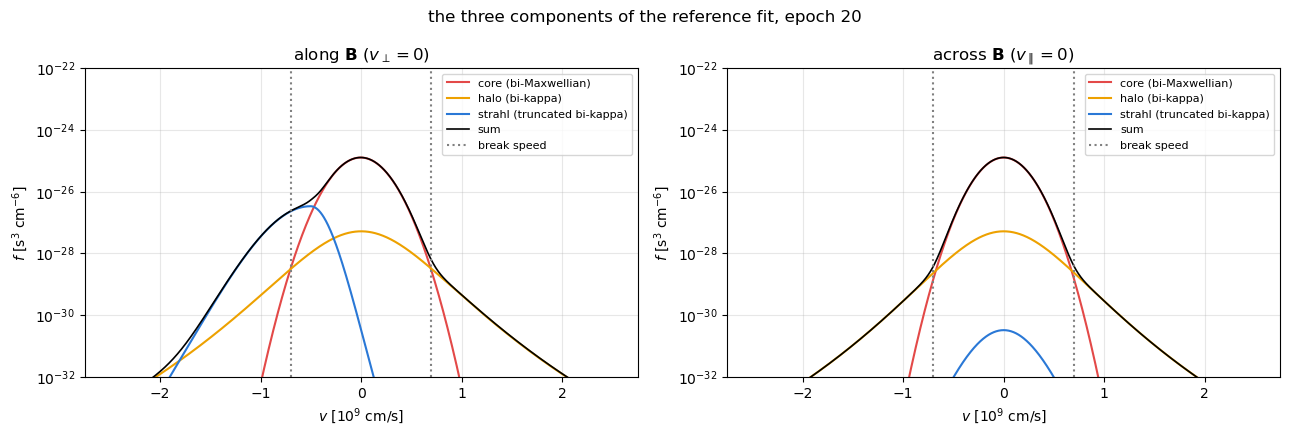

In [3]:
vAxis = np.linspace(-2.5e9, 2.5e9, 1201)
zeros = np.zeros_like(vAxis)
components = {
    'core (bi-Maxwellian)': (biMaxwellian(vAxis, zeros, fitParams['n_c'], fitParams['u_par_c'], fitParams['v_th_par_c'], fitParams['v_th_perp_c']),
                             biMaxwellian(zeros, vAxis, fitParams['n_c'], fitParams['u_par_c'], fitParams['v_th_par_c'], fitParams['v_th_perp_c']), '#e34948'),
    'halo (bi-kappa)': (biKappa(vAxis, zeros, fitParams['n_h'], 0.0, fitParams['v_th_par_h'], fitParams['v_th_perp_h'], fitParams['kappa_h']),
                        biKappa(zeros, vAxis, fitParams['n_h'], 0.0, fitParams['v_th_par_h'], fitParams['v_th_perp_h'], fitParams['kappa_h']), '#eda100'),
    'strahl (truncated bi-kappa)': (strahlTruncatedBiKappa(vAxis, zeros, fitParams['n_b'], fitParams['u_par_b'], fitParams['v_th_par_b'], fitParams['v_th_perp_b'], fitParams['kappa_b']),
                                    strahlTruncatedBiKappa(zeros, vAxis, fitParams['n_b'], fitParams['u_par_b'], fitParams['v_th_par_b'], fitParams['v_th_perp_b'], fitParams['kappa_b']), '#2a78d6'),
}
totalPar = coreHaloStrahlModel(vAxis, zeros, fitParams)
totalPerp = coreHaloStrahlModel(zeros, vAxis, fitParams)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for label, (alongPar, alongPerp, color) in components.items():
    axes[0].semilogy(vAxis / 1e9, alongPar, color=color, label=label)
    axes[1].semilogy(vAxis / 1e9, alongPerp, color=color, label=label)
axes[0].semilogy(vAxis / 1e9, totalPar, 'k', linewidth=1.2, label='sum')
axes[1].semilogy(vAxis / 1e9, totalPerp, 'k', linewidth=1.2, label='sum')
for ax, title in zip(axes, (r'along $\mathbf{B}$ ($v_\perp = 0$)', r'across $\mathbf{B}$ ($v_\parallel = 0$)')):
    for sign in (-1, 1):
        ax.axvline(sign * breakSpeed / 1e9, color='0.5', linestyle=':', label='break speed' if sign > 0 else None)
    ax.set_ylim(1e-32, 1e-22); ax.set_xlabel(r'$v$ [$10^9$ cm/s]'); ax.set_ylabel(r'$f$ [s$^3$ cm$^{-6}$]')
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle('the three components of the reference fit, epoch %d' % EPOCH); fig.tight_layout()

What each parameter does, and why they cannot all be fitted at once:

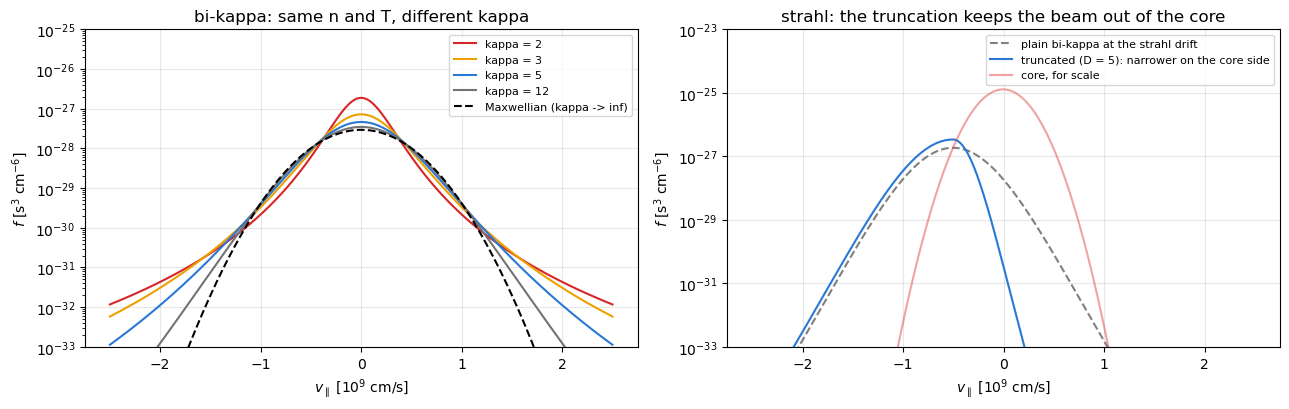

In [4]:
haloWidth, haloDensity = fitParams['v_th_par_h'], fitParams['n_h']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for kappa, color in ((2.0, '#d62728'), (3.0, '#eda100'), (5.0, '#2a78d6'), (12.0, '0.45')):
    axes[0].semilogy(vAxis / 1e9, biKappa(vAxis, zeros, haloDensity, 0.0, haloWidth, haloWidth, kappa), color=color, label=f'kappa = {kappa:g}')
axes[0].semilogy(vAxis / 1e9, biMaxwellian(vAxis, zeros, haloDensity, 0.0, haloWidth, haloWidth), 'k--', label='Maxwellian (kappa -> inf)')
axes[0].set_title('bi-kappa: same n and T, different kappa'); axes[0].set_ylim(1e-33, 1e-25)

beam = dict(n=fitParams['n_b'], u_par=fitParams['u_par_b'], v_th_par=fitParams['v_th_par_b'], v_th_perp=fitParams['v_th_perp_b'], kappa=fitParams['kappa_b'])
axes[1].semilogy(vAxis / 1e9, biKappa(vAxis, zeros, **beam), color='0.5', linestyle='--', label='plain bi-kappa at the strahl drift')
axes[1].semilogy(vAxis / 1e9, strahlTruncatedBiKappa(vAxis, zeros, **beam), color='#2a78d6', label=f'truncated (D = {STRAHL_TRUNCATION_D}): narrower on the core side')
axes[1].semilogy(vAxis / 1e9, components['core (bi-Maxwellian)'][0], color='#e34948', alpha=0.5, label='core, for scale')
axes[1].set_title('strahl: the truncation keeps the beam out of the core'); axes[1].set_ylim(1e-33, 1e-23)
for ax in axes:
    ax.set_xlabel(r'$v_\parallel$ [$10^9$ cm/s]'); ax.set_ylabel(r'$f$ [s$^3$ cm$^{-6}$]'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()

Two things to take from these curves:

- **A low-$\kappa$ halo and a Maxwellian core overlap almost everywhere.** Halo density
  and width trade against each other, and against the core, wherever the tail is faint.
  Unconstrained, the halo becomes a second, slightly hotter core.
- **A strahl with a free width can imitate a drifting core** unless its drift is kept
  suprathermal.

This is why the fit is staged and every parameter has a range (sections 3 and 4).

## 2. Initial guesses from the data

`seedFromData` builds the initial guesses from the measured grid, the RPW density, the
break energy and the PAD verdict (notebook 03):

| component | initial guess | from |
|---|---|---|
| core | $n_c = 0.8\, n_{sc}$ (RPW); drift and widths from the weighted moments of the detected pixels below 70 eV, widths rescaled so that the peak PSD matches $n / (\pi^{3/2} v_{th\parallel} v_{th\perp}^2)$ | data |
| halo | $n_h = 0.03\, n_c$, $T_h = 5\, T_c$, $\kappa_h = 5$, $u_{\parallel h} = 0$ (free, starts at rest) | typical solar-wind ratios |
| strahl | side from the PAD verdict, $n_b = 0.01\, n_c$, drift and width from the break speed, $\kappa_b = 5$, perpendicular width from the PAD width | PAD + break |

Stages B and C re-anchor the halo and strahl guesses on the *fitted* core and the break
speed (section 3), so the numbers below only start stage A.

In [5]:
from evdf_poisson import loadEpoch, detectStrahlFromPad, seedFromData
from evdf_poisson.plotting import plotMeasuredVdf

grid, psd, counts, epochNs, scDensity = loadEpoch(EXAMPLE_FILE, EPOCH)
detection = detectStrahlFromPad(EXAMPLE_FILE, EPOCH, breakEnergyEv)
seeds = seedFromData(psd, counts, grid, strahlDetection=detection, scDensity=scDensity, breakEnergyEv=breakEnergyEv)
seedParams = {name: float(seeds[name]) for name in ALL_PARAM_NAMES}
print(f"PAD verdict: {detection['class']} (sign {detection['sign']}, width {detection['paw_anti' if detection['sign'] < 0 else 'paw_par']:.0f} deg)   RPW density {scDensity:.1f} cm^-3")

comparison = pd.DataFrame({'seed': seedParams, 'reference fit': {name: fitParams[name] for name in ALL_PARAM_NAMES}})
comparison['fit / seed'] = (comparison['reference fit'] / comparison['seed']).replace([np.inf, -np.inf], np.nan)   # u_par_h starts at 0
comparison.map(lambda value: '' if np.isnan(value) else f'{value:.3g}')

PAD verdict: anti_strong (sign -1, width 24 deg)   RPW density 24.3 cm^-3


,seed,reference fit,fit / seed
n_c,19.6,9.36,0.477
u_par_c,2.09e+07,-4.72e+06,-0.226
v_th_par_c,2.1e+08,2.42e+08,1.15
v_th_perp_c,2.32e+08,2.32e+08,1
n_h,0.589,0.186,0.315
u_par_h,0,4.63e+06,
v_th_par_h,4.7e+08,4.84e+08,1.03
v_th_perp_h,4.7e+08,4.55e+08,0.966
kappa_h,5,5.06,1.01
n_b,0.196,0.134,0.684


The initial guesses drawn over the data, with the reference fit for comparison. The
core starts at 0.8 times the RPW density, which is above what EAS measures on these
days (calibration factor, notebook 06), so stage A lowers it. Halo and strahl are
placeholders that stages B and C replace.

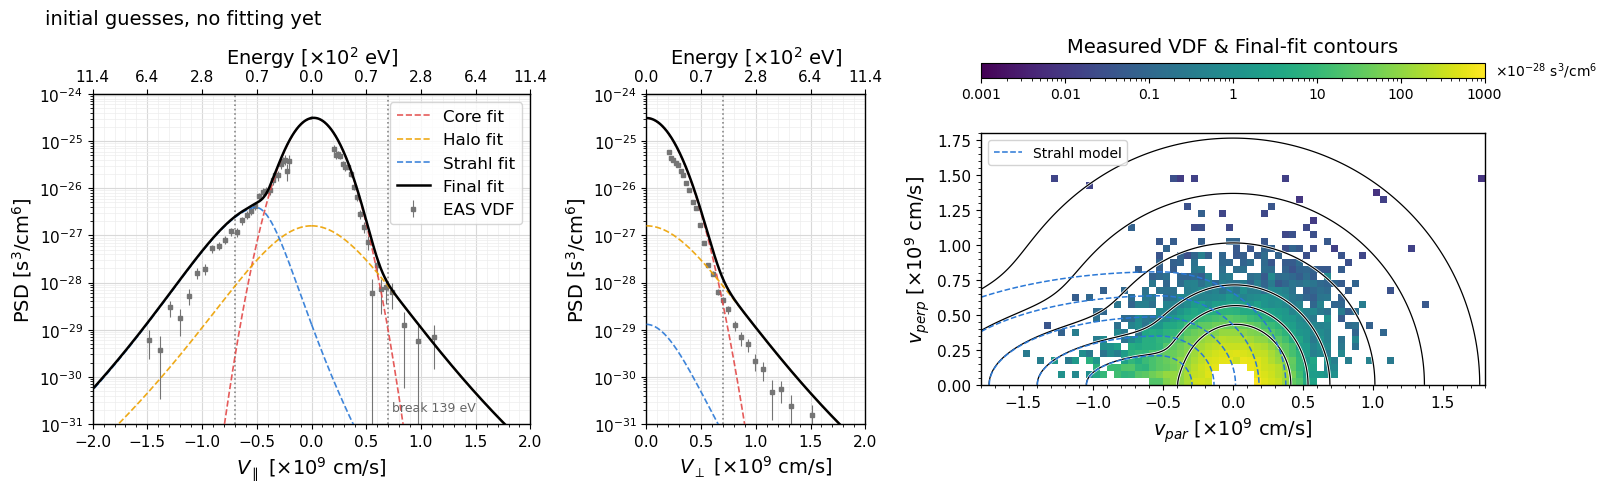

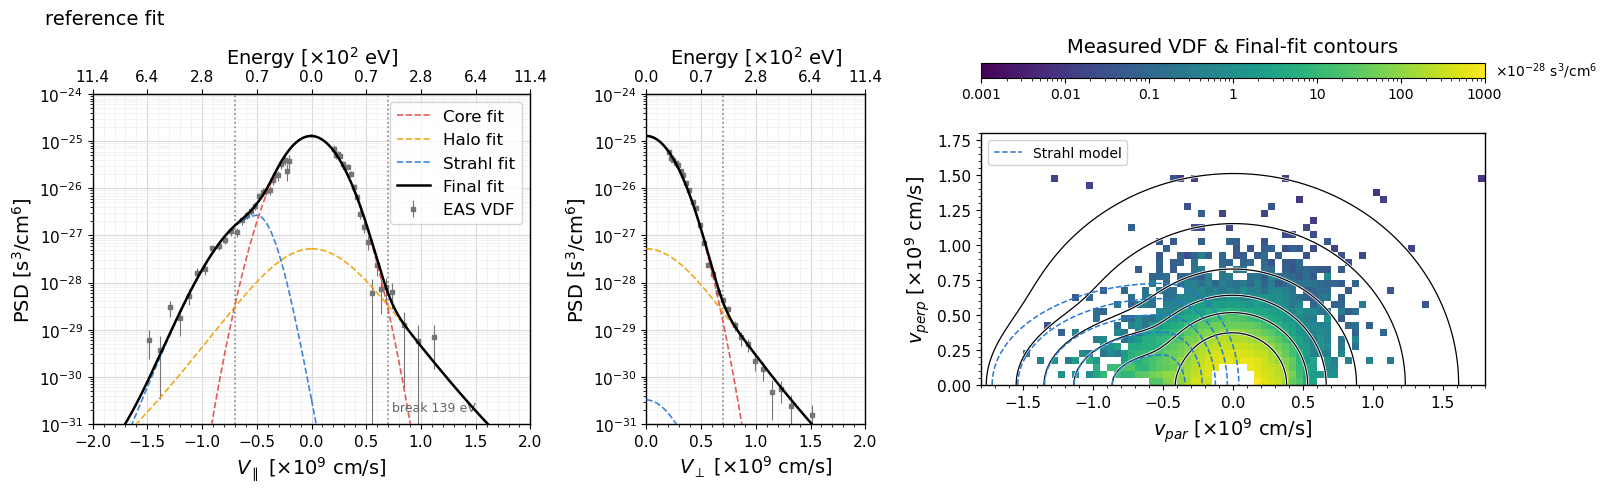

In [6]:
fig = plotMeasuredVdf(grid, psd, counts, params=seedParams, breakEnergyEv=breakEnergyEv,
                      timeLabel='initial guesses, no fitting yet')
fig = plotMeasuredVdf(grid, psd, counts, params={name: fitParams[name] for name in ALL_PARAM_NAMES}, breakEnergyEv=breakEnergyEv,
                      timeLabel='reference fit')

## 3. The parameter ranges

Every free parameter moves inside a range anchored to a measured quantity (the RPW
density, the fitted core width, the break speed, the PAD width), so the ranges scale
with the plasma. Stage by stage (notebook 05 runs them):

**Stage A, core** (all pixels below the break)

| parameter | initial value | allowed range |
|---|---|---|
| $n_c$ | $0.8\, n_{sc}$ (RPW density) | $[0,\ 2\, n_{sc}]$ |
| $u_{\parallel c}$ | 0 | $\pm 1.5\times10^8$ cm/s (free sign) |
| $v_{th\parallel c}$, $v_{th\perp c}$ | from the peak PSD, $(n / \pi^{3/2} f_\text{peak})^{1/3}$ | $[10^7,\ 8\times10^8]$ cm/s |

**Stage B, halo** (above the break, outside both 30 deg cones; core frozen)

| parameter | initial value | allowed range |
|---|---|---|
| $n_h$ | $0.03\, n_c^\text{fit}$ | $[10^{-5},\ 0.2] \times n_c^\text{fit}$ |
| $u_{\parallel h}$ | 0 | $\pm 0.2\, v_{th\perp h}^\text{seed}$ |
| $v_{th\parallel h}$, $v_{th\perp h}$ | $\sqrt{5}\, v_{th c}^\text{fit}$ ($T_h = 5\,T_c$) | $\ge 2 \times$ the fitted core width |
| $\kappa_h$ | 5 | $[2,\ 12]$ |

**Stage C, strahl** (the 30 deg cone on the detected side; core and halo frozen)

| parameter | initial value | allowed range |
|---|---|---|
| $n_b$ | $0.01\, n_{sc}$ | $[0,\ 0.5\, n_{sc}]$ |
| $u_{\parallel b}$ | sign $\times\ 0.9\, v_\text{break}$ | sign $\times [0.3,\ 3]\, v_\text{break}$ |
| $v_{th\parallel b}$ | $0.5\, v_\text{break}$ | $[2\times10^7,\ 1.5\times10^9]$ cm/s |
| $v_{th\perp b}$ | $\tan(\text{PAW}/2)\,\lvert u_{\parallel b}\rvert$ | tied to $u_{\parallel b}$ during this stage |
| $\kappa_b$ | 5 | $[1.7,\ 20]$ |

**Stage D, joint**: all 14 parameters free inside these ranges. The strahl drift is
locked to $\pm 20\,\%$ of its stage-C value, and its perpendicular width may move
within $[0.3, 3]$ times the PAD anchor.

The numbers are constants of `evdf_poisson/staged_fit.py`:

In [7]:
import evdf_poisson.staged_fit as stagedFit

constants = {name: getattr(stagedFit, name) for name in dir(stagedFit)
             if name.isupper() and not name.endswith('NAMES')}
pd.Series(constants).to_frame('value')

,value
BREAK_ENERGY_CORE_TEMPERATURE_FACTOR,7.7
BREAK_ENERGY_LIMITS_EV,"(40.0, 300.0)"
CORE_DENSITY_BOX_FACTOR,2.0
CORE_DENSITY_SEED_FRACTION,0.8
CORE_DRIFT_BOUND_CMS,150000000.0
CORE_WIDTH_BOUNDS_CMS,"(10000000.0, 800000000.0)"
HALO_DENSITY_CEILING_CORE_FRACTION,0.2
HALO_DRIFT_BOUND_IN_WIDTHS,0.2
HALO_DRIFT_PARAM_NAME,u_par_h
HALO_SEED_DENSITY_FRACTION,0.03


## 4. Why the fit is staged

Released all at once on a distribution that is 90 % core, the 14 parameters do not
converge to the physical answer: the halo turns into a second, slightly hotter core and
the strahl into a drifting copy of the core (section 1). So:

1. each component is first fitted on the pixels where it dominates, the others frozen;
2. its ranges are anchored to the previous result;
3. only then is everything released together, inside those ranges.

Notebook 05 runs the four stages on this epoch. Notebook 07 shows that the objective
(Poisson versus chi-square) matters as much as the staging.

## Summary

- Core = bi-Maxwellian, halo = bi-kappa, strahl = drifting truncated bi-kappa;
  14 parameters, thermal speeds with $v_{th} = \sqrt{2 k_B T / m_e}$.
- Initial guesses come from the data: moments below 70 eV, RPW density, break energy,
  PAD verdict.
- Ranges are anchored to measured quantities and re-derived stage by stage.